## Fino podešavanje RoBERTa-e za prepoznavanje imenovanih entiteta - Srpski WikiANN

Zadatak - Izvršiti fine-tuning RoBERTa modela za prepoznavanje imenovanih entiteta. Pronaći neki od dostupnih skupova podataka (ne koristiti isti dataset kao sa računskih vežbi; ukoliko je dataset preveliki, selektovati određeni broj instanci). Izvršiti fine-tuning RoBERTa modela uz pomoć Trainer klase. Eksperimentisati sa različitim vrednostima hiperparametara i pratiti performance modela.

### Ucitavanje alata

In [1]:
import os
import gc
import re
import json
import time
import types
import shutil
import dataclasses
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import datasets
import transformers
from datasets import load_dataset, DatasetDict
from transformers import (
    AutoConfig,
    AutoTokenizer,
    AutoModel,
    AutoModelForTokenClassification,
    DataCollatorForTokenClassification,
    TrainingArguments,
    Trainer,
    pipeline,
    set_seed,
)
from seqeval.metrics import precision_score, recall_score, f1_score, accuracy_score, classification_report
from seqeval.metrics.sequence_labeling import get_entities
from sklearn.metrics import confusion_matrix

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "not available - training will be slow")

c:\Users\stefa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


GPU: NVIDIA GeForce RTX 5070 Ti


In [2]:
#  Konfiguracija
SEED = 42
DATASET_NAME = "unimelb-nlp/wikiann"
DATASET_LANG = "sr"  # Srpski jezik
MODEL_CHECKPOINT = "FacebookAI/xlm-roberta-base"  # visejezicna RoBERTa, pokriva srpski
MAX_LENGTH = 128  # maksimalan brok podtokena po recenici

# Broj instanci koriscenih po podeli (None = cela podela).
# Mnogi modeli su obuceni u eksperimentima, tako da su obucavanje/validacija poduzorkovani
# Test podela se cuva ceo radi pouzdane konacne procene
N_SAMPLES = {"train": 10_000, "validation": 2_000, "test": None}

OUTPUT_DIR = "ner_roberta_sr"
CHECKPOINT_DIR = os.path.join(OUTPUT_DIR, "checkpoints")
BEST_MODEL_DIR = os.path.join(OUTPUT_DIR, "best_model")
RESULTS_DIR = os.path.join(OUTPUT_DIR, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

USE_FP16 = torch.cuda.is_available()  
set_seed(SEED)
sns.set_theme(style="whitegrid")

# Cuva JSON fajlove u folderu results
def save_json(obj, filename):
    with open(os.path.join(RESULTS_DIR, filename), "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False, default=float)

# Oslobadjanje graficke memorije
def free_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

### Ucitavanje dataseta

WikiANN je visejezicni NER skup podataka napravljen od Vikipedije: pominjanja entiteta se preuzimaju iz linkova ka clancima Vikipedije i otkucavaju se kao osoba (PER), organizacija (ORG) ili lokacija (LOC).

In [3]:
raw_datasets = load_dataset(DATASET_NAME, DATASET_LANG)
print(raw_datasets)
print(raw_datasets["train"].features)

DatasetDict({
    validation: Dataset({
        features: ['tokens', 'ner_tags', 'langs', 'spans'],
        num_rows: 10000
    })
    test: Dataset({
        features: ['tokens', 'ner_tags', 'langs', 'spans'],
        num_rows: 10000
    })
    train: Dataset({
        features: ['tokens', 'ner_tags', 'langs', 'spans'],
        num_rows: 20000
    })
})
{'tokens': List(Value('string')), 'ner_tags': List(ClassLabel(names=['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC'])), 'langs': List(Value('string')), 'spans': List(Value('string'))}


In [4]:
dataset_label_names = raw_datasets["train"].features["ner_tags"].feature.names

for i in range(5):
    example = raw_datasets["train"][i]
    print(" ".join(f"{tok}/{dataset_label_names[tag]}" for tok, tag in zip(example["tokens"], example["ner_tags"])))
    print()

Кресвел/B-LOC (/I-LOC Северна/I-LOC Каролина/I-LOC )/I-LOC

на/O пријатељској/O утакмици/O против/O Србије/B-ORG и/I-ORG Црне/I-ORG Горе/I-ORG ./O

Преусмери/O Едмондо/B-PER де/I-PER Амичис/I-PER

У/O финалу/O је/O победио/O Роџера/B-PER Федерера/I-PER резултатом/O 6-3/O ,/O 4-6/O ,/O 6-3/O ,/O 6-4/O ./O

Клеј/B-LOC Сити/I-LOC (/I-LOC Индијана/I-LOC )/I-LOC



### Izbor podskupa instanci

Fino podesavanje se ponavlja za svaku kombinaciju hiperparametara, tako da se koristi slucajni podskup podela za niz i validaciju (velicine podecene u `N_SAMPLES`). Isti podskup se koristi za svaki eksperiment, sto odrzava poredjenje fer. Cuvaju se samo kolone potrebne za NER („tokeni“, `ner_tags`).

In [5]:
# Slučajni podskup od n instanci (cela podela ako je n None ili veće od podele)
def subsample(split, n, seed=SEED):
    if n is None or n >= len(split):
        return split
    
    return split.shuffle(seed=seed).select(range(n))

ds = DatasetDict({name: subsample(split, N_SAMPLES.get(name)) for name, split in raw_datasets.items()})
ds = ds.remove_columns([c for c in ds["train"].column_names if c not in ("tokens", "ner_tags")])

print(ds)
pd.DataFrame({
    "full split": {name: len(split) for name, split in raw_datasets.items()},
    "used": {name: len(split) for name, split in ds.items()},
})

DatasetDict({
    validation: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 10000
    })
    train: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 10000
    })
})


,full split,used
validation,10000,2000
test,10000,10000
train,20000,10000


### Analiza dataseta

Broj instanci, broj tokena i distribucija oznaka (nivo tokena i nivo entiteta) za podatke koji se stvarno koriste.

In [6]:
def split_statistics(split):
    lengths = np.array([len(tokens) for tokens in split["tokens"]])  # Duzine
    tag_sequences = [[dataset_label_names[t] for t in tags] for tags in split["ner_tags"]]  # Tagovane sekvence
    n_entities = sum(len(get_entities(seq)) for seq in tag_sequences)  # Broj entiteta

    return {
        "instances": len(split),  # Instance
        "tokens": int(lengths.sum()),  # Tokeni
        "avg tokens/sentence": round(float(lengths.mean()), 2),  # Prosek tokeni/recencie
        "median length": int(np.median(lengths)),  # Srednja duzina
        "max length": int(lengths.max()),  # Maksimalna duzina
        "entities": n_entities,  # Broj entiteta
        "entities/sentence": round(n_entities / len(split), 2),  # Prosek entiteti/recenice
    }

# Cuvanje u JSON formatu i stampanje statistickog dataseta
stats_df = pd.DataFrame.from_dict({name: split_statistics(split) for name, split in ds.items()}, orient="index")
save_json(stats_df.to_dict(orient="index"), "dataset_statistics.json")
stats_df

,instances,tokens,avg tokens/sentence,median length,max length,entities,entities/sentence
validation,2000,14317,7.16,6,47,2310,1.16
test,10000,72188,7.22,6,148,11578,1.16
train,10000,71749,7.17,6,47,11508,1.15


In [7]:
# Distribucija oznaka na nivou tokena
token_label_counts = pd.DataFrame({
    name: pd.Series([dataset_label_names[t] for tags in split["ner_tags"] for t in tags]).value_counts()
    for name, split in ds.items()
}).reindex(dataset_label_names).fillna(0).astype(int)
token_label_pct = (token_label_counts / token_label_counts.sum() * 100).round(2)

# Distribucija na nivou entiteta
entity_counts = pd.DataFrame({
    name: pd.Series([
        entity_type
        for tags in split["ner_tags"]
        for entity_type, _, _ in get_entities([dataset_label_names[t] for t in tags])
    ]).value_counts()
    for name, split in ds.items()
}).fillna(0).astype(int)

# Stampanje distribucija kao datasetova
print("Token-level label distribution")
display(pd.concat({"count": token_label_counts, "%": token_label_pct}, axis=1))
print("Entity-level distribution")
display(entity_counts)

Token-level label distribution


count                        %              
      validation   test  train validation   test  train
O           7412  37048  37010      51.77  51.32  51.58
B-PER        896   4139   4017       6.26   5.73   5.60
I-PER       1182   5962   5601       8.26   8.26   7.81
B-ORG        690   3657   3693       4.82   5.07   5.15
I-ORG       1496   7780   7701      10.45  10.78  10.73
B-LOC        724   3782   3798       5.06   5.24   5.29
I-LOC       1917   9820   9929      13.39  13.60  13.84

Entity-level distribution


,validation,test,train
PER,896,4139,4017
LOC,724,3782,3798
ORG,690,3657,3693


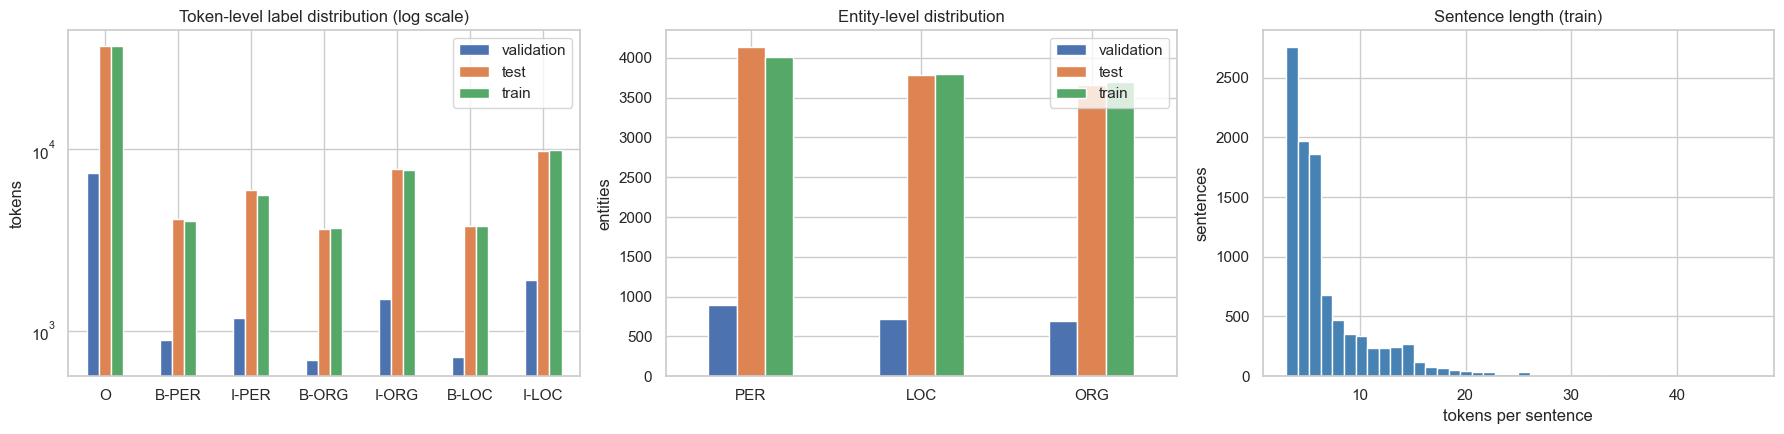

In [8]:
# Grafovi distribucija
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

token_label_counts.plot.bar(ax=axes[0], logy=True, rot=0)
axes[0].set_title("Token-level label distribution (log scale)")
axes[0].set_ylabel("tokens")

entity_counts.plot.bar(ax=axes[1], rot=0)
axes[1].set_title("Entity-level distribution")
axes[1].set_ylabel("entities")

axes[2].hist([len(tokens) for tokens in ds["train"]["tokens"]], bins=40, color="steelblue")
axes[2].set_title("Sentence length (train)")
axes[2].set_xlabel("tokens per sentence")
axes[2].set_ylabel("sentences")

plt.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "dataset_analysis.png"), dpi=150, bbox_inches="tight")
plt.show()

In [9]:
# Kompajliranje cirilice i latinice
CYRILLIC = re.compile(r"[\u0400-\u04FF]")
LATIN = re.compile(r"[A-Za-z\u00C0-\u024F]")

train_tokens = [tok for tokens in ds["train"]["tokens"] for tok in tokens]
script_counts = pd.Series({
    "Cyrillic": sum(bool(CYRILLIC.search(t)) for t in train_tokens),
    "Latin": sum(bool(LATIN.search(t)) and not CYRILLIC.search(t) for t in train_tokens),
})
script_counts["other (digits, punctuation)"] = len(train_tokens) - script_counts.sum()
(script_counts / len(train_tokens) * 100).round(2).to_frame("% of train tokens")

,% of train tokens
Cyrillic,68.06
Latin,3.80
"other (digits, punctuation)",28.14


### Definisanje NER klasa

WikiANN koristi IOB2 semu: `B-X` oznacava prvi token entiteta tipa X, `I-X` token unutar istog entiteta, a `O` token izvan bilo kog entiteta.

| Labela | Znacenje |
|---|---|
| `O` | nije entitet |
| `B-PER` / `I-PER` | osoba |
| `B-ORG` / `I-ORG` | organizacija |
| `B-LOC` / `I-LOC` | lokacija |

In [10]:
label_list = ["O", "B-PER", "I-PER", "B-ORG", "I-ORG", "B-LOC", "I-LOC"]
assert label_list == dataset_label_names, f"Label order differs from the dataset: {dataset_label_names}"

id2label = {i: label for i, label in enumerate(label_list)}
label2id = {label: i for i, label in enumerate(label_list)}
NUM_LABELS = len(label_list)
ENTITY_TYPES = sorted({label[2:] for label in label_list if label != "O"})

print("id2label    :", id2label)
print("entity types:", ENTITY_TYPES)

id2label    : {0: 'O', 1: 'B-PER', 2: 'I-PER', 3: 'B-ORG', 4: 'I-ORG', 5: 'B-LOC', 6: 'I-LOC'}
entity types: ['LOC', 'ORG', 'PER']


### Ucitavanje RoBERTa tokenizera

In [11]:
model_config = AutoConfig.from_pretrained(MODEL_CHECKPOINT)
tokenizer_kwargs = {"add_prefix_space": True} if model_config.model_type == "roberta" else {}
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT, **tokenizer_kwargs)

assert tokenizer.is_fast, "A fast tokenizer is required (word_ids() is used for label alignment)"
print(f"model type     : {model_config.model_type}")
print(f"tokenizer      : {type(tokenizer).__name__}")
print(f"vocabulary size: {len(tokenizer):,}")
print(f"special tokens : {tokenizer.all_special_tokens}")

model type     : xlm-roberta
tokenizer      : XLMRobertaTokenizer
vocabulary size: 250,002
special tokens : ['<s>', '</s>', '<unk>', '<pad>', '<mask>']


### Tokenizacija dataseta

In [12]:
example = ds["train"][0]
encoding = tokenizer(example["tokens"], is_split_into_words=True)
word_ids = encoding.word_ids()

pd.DataFrame({
    "sub-token": encoding.tokens(),
    "word_id": word_ids,
    "word": [example["tokens"][w] if w is not None else "" for w in word_ids],
}).T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
sub-token,<s>,▁Глас,▁му,▁поза,ј,м,љује,▁Чар,ли,▁Ад,лер,▁,.,</s>
word_id,NaN,0.0,1.0,2.0,2.0,2.0,2.0,3.0,3.0,4.0,4.0,5.0,5.0,NaN
word,,Глас,му,позајмљује,позајмљује,позајмљује,позајмљује,Чарли,Чарли,Адлер,Адлер,.,.,


In [13]:
# Tokenizacija batch-a
def tokenize_batch(batch):
    encodings = tokenizer(batch["tokens"], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    encodings["word_ids"] = [encodings.word_ids(i) for i in range(len(batch["tokens"]))]

    return encodings

tokenized_datasets = ds.map(tokenize_batch, batched=True, desc="Tokenizing")
print(tokenized_datasets)

Tokenizing: 100%|██████████| 10000/10000 [00:00<00:00, 36251.67 examples/s]

DatasetDict({
    validation: Dataset({
        features: ['tokens', 'ner_tags', 'input_ids', 'attention_mask', 'word_ids'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['tokens', 'ner_tags', 'input_ids', 'attention_mask', 'word_ids'],
        num_rows: 10000
    })
    train: Dataset({
        features: ['tokens', 'ner_tags', 'input_ids', 'attention_mask', 'word_ids'],
        num_rows: 10000
    })
})


In [14]:
subtoken_lengths = pd.Series([len(ids) for ids in tokenized_datasets["train"]["input_ids"]])
word_subtokens = sum(sum(w is not None for w in wids) for wids in tokenized_datasets["train"]["word_ids"])

print(f"sub-tokens per sentence : mean={subtoken_lengths.mean():.1f}, "
      f"95th percentile={subtoken_lengths.quantile(0.95):.0f}, max={subtoken_lengths.max()}")
print(f"sub-tokens per word     : {word_subtokens / stats_df.loc['train', 'tokens']:.2f}")
print(f"sentences reaching MAX_LENGTH={MAX_LENGTH} (possibly truncated): {(subtoken_lengths >= MAX_LENGTH).sum()}")

sub-tokens per sentence : mean=14.9, 95th percentile=30, max=86
sub-tokens per word     : 1.80
sentences reaching MAX_LENGTH=128 (possibly truncated): 0


### Poravnanje NER oznaka sa podtokenima

Tagovi pripadaju recima, model predvidja jednu oznaku po podtokenu. Pravilo poravnanja:

* specijalni tokeni (`<s>`, `</s>`) → `-100`, koje PyTorch-ov gubitak unakrsne entropije ignorise;
* prvi podtoken reci → oznaka reci;
* preostali podtokeni reci → `-100`.

In [15]:
def align_labels_with_subtokens(batch):
    all_labels = []
    
    for word_ids, word_tags in zip(batch["word_ids"], batch["ner_tags"]):
        labels, previous_word = [], None
        for word_id in word_ids:
            if word_id is None:  # Specijalni token
                labels.append(-100)
            elif word_id != previous_word:  # Prvi podtoken reci
                labels.append(word_tags[word_id])
            else:  # Podtoken za nastavak
                labels.append(-100)
            previous_word = word_id
        all_labels.append(labels)

    return {"labels": all_labels}

tokenized_datasets = tokenized_datasets.map(
    align_labels_with_subtokens,
    batched=True,
    remove_columns=["tokens", "ner_tags", "word_ids"],
    desc="Aligning labels",
)
print(tokenized_datasets)

Aligning labels: 100%|██████████| 10000/10000 [00:00<00:00, 427689.08 examples/s]

DatasetDict({
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 10000
    })
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 10000
    })
})


In [16]:
row = tokenized_datasets["train"][0]
display(pd.DataFrame({
    "sub-token": tokenizer.convert_ids_to_tokens(row["input_ids"]),
    "label id": row["labels"],
    "label": [id2label[l] if l != -100 else "(ignored)" for l in row["labels"]],
}).T)

# Provera ispravnosti: jedan oznaceni podtoken po reci
n_labelled = sum(sum(l != -100 for l in labels) for labels in tokenized_datasets["train"]["labels"])
print(f"labelled sub-tokens: {n_labelled:,} | words in train: {int(stats_df.loc['train', 'tokens']):,}")

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
sub-token,<s>,▁Глас,▁му,▁поза,ј,м,љује,▁Чар,ли,▁Ад,лер,▁,.,</s>
label id,-100,0,0,0,-100,-100,-100,1,-100,2,-100,0,-100,-100
label,(ignored),O,O,O,(ignored),(ignored),(ignored),B-PER,(ignored),I-PER,(ignored),O,(ignored),(ignored)


labelled sub-tokens: 71,749 | words in train: 71,749


### Kreiranje sistema za prikupljanje podataka

Recenice imaju razlicite duzine. `DataCollatorForTokenClassification` dinamicki dopunjava svaku grupu do njenog najduzeg niza: `input_ids` sa tokenom za dopunjavanje, `attention_mask` sa 0 i `labels` sa `-100`, tako da dopunjavanje ne utice na gubitak.

In [17]:
data_collator = DataCollatorForTokenClassification(tokenizer=tokenizer, label_pad_token_id=-100)

sample_batch = data_collator([tokenized_datasets["train"][i] for i in range(4)])
for key, value in sample_batch.items():
    print(f"{key:15s} {tuple(value.shape)}")
    
print(sample_batch["labels"][:2])

input_ids       (4, 15)
attention_mask  (4, 15)
labels          (4, 15)
tensor([[-100,    0,    0,    0, -100, -100, -100,    1, -100,    2, -100,    0,
         -100, -100, -100],
        [-100,    5, -100, -100, -100,    6,    6,    6, -100, -100, -100, -100,
         -100, -100, -100]])


### Ucitavanje istrenirane RoBERTa-e

In [18]:
pretrained_encoder = AutoModel.from_pretrained(MODEL_CHECKPOINT)
cfg = pretrained_encoder.config

print(type(pretrained_encoder).__name__)
print(f"layers={cfg.num_hidden_layers}, hidden size={cfg.hidden_size}, attention heads={cfg.num_attention_heads}")
print(f"parameters: {sum(p.numel() for p in pretrained_encoder.parameters()) / 1e6:.1f} M")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2018.57it/s]
[transformers] XLMRobertaModel LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


XLMRobertaModel
layers=12, hidden size=768, attention heads=12
parameters: 278.0 M


### Dodavanje zaglavlja klasifikacije tokena

In [19]:
# Istrenirani RoBERTa enkoder + sveže inicijalizovana glava za klasifikaciju tokena
def build_model():
    return AutoModelForTokenClassification.from_pretrained(
        MODEL_CHECKPOINT,
        num_labels=NUM_LABELS,
        id2label=id2label,
        label2id=label2id,
    )

set_seed(SEED)
model = build_model()

print("Classification head:")
print(" ", model.dropout)
print(" ", model.classifier)
same_weights = torch.equal(pretrained_encoder.get_input_embeddings().weight, model.get_input_embeddings().weight)
print("Encoder weights identical to the pretrained model from step 9:", same_weights)
print(f"trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6:.1f} M")

del pretrained_encoder
free_memory()

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 1882.75it/s]
[transformers] XLMRobertaForTokenClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.weight           | MISSING    | 
classifier.bias             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Classification head:
  Dropout(p=0.1, inplace=False)
  Linear(in_features=768, out_features=7, bias=True)
Encoder weights identical to the pretrained model from step 9: True
trainable parameters: 277.5 M


### Definicija `compute_metrics`

NER se procenjuje na nivou entiteta pomocu `seqeval`: predvidjeni entitet se racuna kao tacan samo ako se i njegove granice i tip podudaraju sa zlatnim entitetom.

* Precision = tacni predviđeni entiteti / svi predvidjeni entiteti
* Recall = tacni predvidjeni entiteti / svi zlatni entiteti
* F1 = harmonijska sredina precision i recall

In [20]:
# Logitske vrednosti (batch, seq, labels) + identifikatori oznaka (batch, seq) -> liste nizova oznaka
def align_predictions(predictions, label_ids):
    pred_ids = np.argmax(predictions, axis=-1)
    y_true, y_pred = [], []

    for pred_row, label_row in zip(pred_ids, label_ids):
        mask = label_row != -100
        y_true.append([id2label[int(l)] for l in label_row[mask]])
        y_pred.append([id2label[int(p)] for p in pred_row[mask]])

    return y_true, y_pred

def compute_metrics(eval_pred):
    y_true, y_pred = align_predictions(eval_pred.predictions, eval_pred.label_ids)
    
    return {
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "accuracy": accuracy_score(y_true, y_pred),
    }

In [21]:
# Provera ispravnosti: savrsena predvidjanja moraju dati P = R = F1 = 1.0
toy_labels = [labels for labels in tokenized_datasets["validation"].select(range(8))["labels"]]
toy_label_ids = np.full((len(toy_labels), max(map(len, toy_labels))), -100)

for i, labels in enumerate(toy_labels):
    toy_label_ids[i, :len(labels)] = labels

perfect_logits = np.eye(NUM_LABELS)[np.clip(toy_label_ids, 0, None)]
compute_metrics(types.SimpleNamespace(predictions=perfect_logits, label_ids=toy_label_ids))

{'precision': np.float64(1.0),
 'recall': np.float64(1.0),
 'f1': np.float64(1.0),
 'accuracy': 1.0}

### Definicija baseline hiperparametara

In [22]:
BASELINE_HP = {
    "learning_rate": 2e-5,
    "per_device_train_batch_size": 16,
    "num_train_epochs": 3,
    "weight_decay": 0.01,
    "warmup_ratio": 0.1,
    "lr_scheduler_type": "linear",
}

EVAL_BATCH_SIZE = 64
pd.Series(BASELINE_HP, name="baseline").to_frame()

,baseline
learning_rate,0.00002
per_device_train_batch_size,16
num_train_epochs,3
weight_decay,0.01
warmup_ratio,0.1
lr_scheduler_type,linear


### Kreiranje `TrainingArguments`

In [23]:
TRAINING_ARG_FIELDS = {f.name for f in dataclasses.fields(TrainingArguments)}

def make_training_args(run_name, hp):
    kwargs = dict(
        output_dir=os.path.join(CHECKPOINT_DIR, run_name),
        run_name=run_name,
        learning_rate=hp["learning_rate"],
        per_device_train_batch_size=hp["per_device_train_batch_size"],
        per_device_eval_batch_size=EVAL_BATCH_SIZE,
        num_train_epochs=hp["num_train_epochs"],
        weight_decay=hp["weight_decay"],
        lr_scheduler_type=hp["lr_scheduler_type"],
        eval_strategy="epoch",
        save_strategy="epoch",
        save_total_limit=1,
        save_only_model=True,
        load_best_model_at_end=True,
        metric_for_best_model="f1",
        greater_is_better=True,
        logging_strategy="steps",
        logging_steps=50,
        fp16=USE_FP16,
        report_to="none",
        seed=SEED,
    )

    if "warmup_ratio" in TRAINING_ARG_FIELDS:  # transformers 4.x
        kwargs["warmup_ratio"] = hp["warmup_ratio"]
    else:  # transformers 5.x
        kwargs["warmup_steps"] = hp["warmup_ratio"]
        
    return TrainingArguments(**kwargs)

baseline_args = make_training_args("baseline", BASELINE_HP)
print(f"output_dir={baseline_args.output_dir} | lr={baseline_args.learning_rate} | "
      f"batch={baseline_args.per_device_train_batch_size} | epochs={baseline_args.num_train_epochs} | fp16={baseline_args.fp16}")

output_dir=ner_roberta_sr\checkpoints\baseline | lr=2e-05 | batch=16 | epochs=3 | fp16=True


### Kreiranje `Trainer`

In [24]:
def make_trainer(model, training_args):
    return Trainer(
        model=model,
        args=training_args,
        train_dataset=tokenized_datasets["train"],
        eval_dataset=tokenized_datasets["validation"],
        data_collator=data_collator,
        processing_class=tokenizer,
        compute_metrics=compute_metrics,
    )

trainer = make_trainer(model, baseline_args)

### Obuka `trainer.train()`

In [25]:
start = time.time()
train_output = trainer.train()
baseline_train_time = time.time() - start

baseline_history = list(trainer.state.log_history) 
print(train_output)
print(f"training time: {baseline_train_time / 60:.1f} min")

Epoch,Training Loss,Validation Loss,Precision,Recall,F1,Accuracy
1,0.209829,0.187581,0.836038,0.869697,0.852536,0.950730
2,0.141388,0.163343,0.884500,0.891775,0.888122,0.959256
3,0.104221,0.156299,0.885253,0.901732,0.893416,0.961563


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.85it/s]


TrainOutput(global_step=1875, training_loss=0.25893486557006834, metrics={'train_runtime': 69.0506, 'train_samples_per_second': 434.464, 'train_steps_per_second': 27.154, 'total_flos': 521359589665728.0, 'train_loss': 0.25893486557006834, 'epoch': 3.0})
training time: 1.2 min


### Procena na osnovu skupa za validaciju i cuvanje rezultata

Zbog `load_best_model_at_end=True`, `trainer.evaluate()` boduje najbolju epohu. Pomocnik ispod se ponovo koristi za svaki eksperiment: on procenjuje, cuva metrike i istoriju obuke (kao JSON i CSV u `RESULTS_DIR`), cuva model u `BEST_MODEL_DIR` ako je do sada najbolji i uklanja checkpointe.

In [26]:
RESULTS = {}  # naziv eksperimenta -> red sazetka
HISTORIES = {}  # naziv eksperimenta -> {"train": DataFrame, "eval": DataFrame}
BEST = {"name": None, "f1": -1.0}  # najbolji eksperiment do sada

# Deli Trainer.state.log_history na redove za gubitak treninga i redove za evaluaciju po epohi
def history_to_frames(log_history):
    train_rows = [h for h in log_history if "loss" in h]
    eval_rows = [h for h in log_history if "eval_loss" in h]
    train_df = pd.DataFrame(train_rows).reindex(columns=["step", "epoch", "loss", "learning_rate"])
    eval_df = pd.DataFrame(eval_rows).drop_duplicates("epoch")
    eval_df.columns = [c.removeprefix("eval_") for c in eval_df.columns]

    return train_df.reset_index(drop=True), eval_df.reset_index(drop=True)

def record_experiment(name, hp, trainer, history, train_time):
    val = trainer.evaluate()
    train_df, eval_df = history_to_frames(history)
    
    HISTORIES[name] = {"train": train_df, "eval": eval_df}
    RESULTS[name] = {
        "experiment": name,
        **hp,
        "best_epoch": int(eval_df.loc[eval_df["f1"].idxmax(), "epoch"]),
        "val_loss": val["eval_loss"],
        "val_precision": val["eval_precision"],
        "val_recall": val["eval_recall"],
        "val_f1": val["eval_f1"],
        "val_accuracy": val["eval_accuracy"],
        "train_time_min": train_time / 60,
    }

    save_json({"hyperparameters": hp, "validation": val, "train_time_s": train_time, "log_history": history},
              f"experiment_{name}.json")
    pd.DataFrame(RESULTS.values()).to_csv(os.path.join(RESULTS_DIR, "experiments.csv"), index=False)

    if val["eval_f1"] > BEST["f1"]:
        trainer.save_model(BEST_MODEL_DIR)
        BEST.update(name=name, f1=val["eval_f1"])
        
    shutil.rmtree(trainer.args.output_dir, ignore_errors=True)

    return val

In [27]:
baseline_val = record_experiment("baseline", BASELINE_HP, trainer, baseline_history, baseline_train_time)

print("Validation results (best epoch):")
display(pd.Series(baseline_val).to_frame("baseline"))
print("Per-epoch validation metrics:")
display(HISTORIES["baseline"]["eval"][["epoch", "loss", "precision", "recall", "f1", "accuracy"]])

del trainer, model
free_memory()

Training Loss,Validation Loss,Epoch,Precision,Recall,F1,Accuracy
0.104221,0.156299,3,0.885253,0.901732,0.893416,0.961563


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.62it/s]

Validation results (best epoch):


,baseline
eval_loss,0.156299
eval_precision,0.885253
eval_recall,0.901732
eval_f1,0.893416
eval_accuracy,0.961563


Per-epoch validation metrics:


,epoch,loss,precision,recall,f1,accuracy
0,1.0,0.187581,0.836038,0.869697,0.852536,0.950730
1,2.0,0.163343,0.884500,0.891775,0.888122,0.959256
2,3.0,0.156299,0.885253,0.901732,0.893416,0.961563


### Definicija kombinacije hiperparametara

| Hiperparametar | Vrednost | Sta kontrolise |
|---|---|---|
| learning rate | 1e-5, 2e-5, 5e-5, 1e-4 | step size, previsok moze destabilizovati prethodno obucene tezine, prenizak nedovoljno prilagodjavanje u nekoliko epoha |
| batch size | 8, 16, 32 | gradijentni sum i broj azuriranja po epohi |
| epochs | 3, 5 | duzina treninga / rizik preprilagodjavanja |
| warm-up and weight decay | 0.1 / 0.01, 0 / 0 | regularizacija i stabilnost u ranoj obuci |
| LR schedule | linear, cosine | kako se LR raspada |

In [28]:
EXPERIMENTS = {
    "baseline":        {},                                  
    "lr_1e-5":         {"learning_rate": 1e-5},
    "lr_5e-5":         {"learning_rate": 5e-5},
    "lr_1e-4":         {"learning_rate": 1e-4},
    "bs_8":            {"per_device_train_batch_size": 8},
    "bs_32":           {"per_device_train_batch_size": 32},
    "epochs_5":        {"num_train_epochs": 5},
    "no_warmup_no_wd": {"warmup_ratio": 0.0, 
                        "weight_decay": 0.0},
    "cosine_lr3e-5_bs32_ep5": {"learning_rate": 3e-5, 
                               "per_device_train_batch_size": 32,
                               "num_train_epochs": 5, 
                               "lr_scheduler_type": "cosine"},
}

experiment_grid = pd.DataFrame({name: {**BASELINE_HP, **overrides} for name, overrides in EXPERIMENTS.items()}).T
experiment_grid

,learning_rate,per_device_train_batch_size,num_train_epochs,weight_decay,warmup_ratio,lr_scheduler_type
baseline,0.00002,16,3,0.01,0.1,linear
lr_1e-5,0.00001,16,3,0.01,0.1,linear
lr_5e-5,0.00005,16,3,0.01,0.1,linear
lr_1e-4,0.0001,16,3,0.01,0.1,linear
bs_8,0.00002,8,3,0.01,0.1,linear
bs_32,0.00002,32,3,0.01,0.1,linear
epochs_5,0.00002,16,5,0.01,0.1,linear
no_warmup_no_wd,0.00002,16,3,0.0,0.0,linear
cosine_lr3e-5_bs32_ep5,0.00003,32,5,0.01,0.1,cosine


### Pokretanje eksperimenata

Za svaku kombinaciju: ucitava novi prethodno trenirani RoBERTa, kreira `TrainingArguments`, kreira `Trainer`, `train()`, `evaluate()` i cuva rezultate. Tabela rezultata se zapisuje svakog pokretanja, tako da se nista ne gubi ako se sesija prekine.

In [29]:
def run_experiment(name, overrides):
    hp = {**BASELINE_HP, **overrides}
    print(f"\n{'=' * 80}\nExperiment: {name}\n{hp}\n{'=' * 80}")

    set_seed(SEED)
    model = build_model()                                   # new pretrained RoBERTa + head
    trainer = make_trainer(model, make_training_args(name, hp))

    start = time.time()
    trainer.train()
    train_time = time.time() - start

    history = list(trainer.state.log_history)
    val = record_experiment(name, hp, trainer, history, train_time)
    print(f"-> val F1={val['eval_f1']:.4f}  P={val['eval_precision']:.4f}  "
          f"R={val['eval_recall']:.4f}  ({train_time / 60:.1f} min)")

    del trainer, model
    free_memory()

for name, overrides in EXPERIMENTS.items():
    if name in RESULTS:
        print(f"Skipping '{name}' (already trained)")
        continue
    run_experiment(name, overrides)

Skipping 'baseline' (already trained)

Experiment: lr_1e-5
{'learning_rate': 1e-05, 'per_device_train_batch_size': 16, 'num_train_epochs': 3, 'weight_decay': 0.01, 'warmup_ratio': 0.1, 'lr_scheduler_type': 'linear'}


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 2142.46it/s]
[transformers] XLMRobertaForTokenClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.weight           | MISSING    | 
classifier.bias             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Precision,Recall,F1,Accuracy
1,0.219098,0.195678,0.837804,0.865368,0.851363,0.949472
2,0.169985,0.167896,0.866976,0.888745,0.877726,0.956251
3,0.138913,0.160057,0.883305,0.897835,0.890511,0.960305


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.86it/s]


Training Loss,Validation Loss,Epoch,Precision,Recall,F1,Accuracy
0.138913,0.160057,3,0.883305,0.897835,0.890511,0.960305


-> val F1=0.8905  P=0.8833  R=0.8978  (1.2 min)

Experiment: lr_5e-5
{'learning_rate': 5e-05, 'per_device_train_batch_size': 16, 'num_train_epochs': 3, 'weight_decay': 0.01, 'warmup_ratio': 0.1, 'lr_scheduler_type': 'linear'}


... (33 outputs left out)

Epoch,Training Loss,Validation Loss,Precision,Recall,F1,Accuracy
1,0.246313,0.187965,0.832020,0.868398,0.849820,0.948634
2,0.175565,0.146148,0.879590,0.891775,0.885641,0.958697
3,0.107459,0.154215,0.861042,0.901299,0.880711,0.958907
4,0.084955,0.142113,0.895726,0.907359,0.901505,0.964708
5,0.070209,0.141137,0.905028,0.911688,0.908346,0.966245


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.07it/s]


Training Loss,Validation Loss,Epoch,Precision,Recall,F1,Accuracy
0.070209,0.141137,5,0.905028,0.911688,0.908346,0.966245


-> val F1=0.9083  P=0.9050  R=0.9117  (1.1 min)


### Poredjenje eksperimenata

Sve obuke sortirane po validaciji F1 (njihove najbolje epohe).

In [30]:
comparison = (pd.DataFrame(RESULTS.values())
              .set_index("experiment")
              .sort_values("val_f1", ascending=False))
comparison.to_csv(os.path.join(RESULTS_DIR, "experiments_comparison.csv"))

metric_cols = ["val_precision", "val_recall", "val_f1", "val_accuracy"]
(comparison.style
 .format({"learning_rate": "{:.0e}", "val_loss": "{:.4f}", "train_time_min": "{:.1f}",
          **{c: "{:.4f}" for c in metric_cols}})
 .background_gradient(subset=["val_f1"], cmap="Greens"))

,learning_rate,per_device_train_batch_size,num_train_epochs,weight_decay,warmup_ratio,lr_scheduler_type,best_epoch,val_loss,val_precision,val_recall,val_f1,val_accuracy,train_time_min
experiment,,,,,,,,,,,,,
bs_8,2e-05,8,3,0.010000,0.100000,linear,3,0.1653,0.9050,0.9160,0.9105,0.9653,2.2
lr_5e-5,5e-05,16,3,0.010000,0.100000,linear,3,0.1453,0.9086,0.9121,0.9103,0.9676,1.1
cosine_lr3e-5_bs32_ep5,3e-05,32,5,0.010000,0.100000,cosine,5,0.1411,0.9050,0.9117,0.9083,0.9662,1.1
epochs_5,2e-05,16,5,0.010000,0.100000,linear,4,0.1666,0.9024,0.9091,0.9058,0.9647,1.9
lr_1e-4,1e-04,16,3,0.010000,0.100000,linear,3,0.1492,0.9008,0.9078,0.9043,0.9662,1.1
bs_32,2e-05,32,3,0.010000,0.100000,linear,3,0.1429,0.8954,0.9082,0.9018,0.9631,0.7
no_warmup_no_wd,2e-05,16,3,0.000000,0.000000,linear,3,0.1525,0.8946,0.9078,0.9012,0.9640,1.1
baseline,2e-05,16,3,0.010000,0.100000,linear,3,0.1563,0.8853,0.9017,0.8934,0.9616,1.2
lr_1e-5,1e-05,16,3,0.010000,0.100000,linear,3,0.1601,0.8833,0.8978,0.8905,0.9603,1.2


In [31]:
# Razlika od osnovne vrednosti (u F1 poenima) za svaki eksperiment
delta = ((comparison["val_f1"] - RESULTS["baseline"]["val_f1"]) * 100).round(2)
delta.to_frame("Δ val F1 vs baseline (points)")

,Δ val F1 vs baseline (points)
experiment,
bs_8,1.71
lr_5e-5,1.69
cosine_lr3e-5_bs32_ep5,1.49
epochs_5,1.23
lr_1e-4,1.09
bs_32,0.84
no_warmup_no_wd,0.77
baseline,0.00
lr_1e-5,-0.29


### Izbor modela sa najboljim validacionim rezultatima

In [32]:
best_name = comparison["val_f1"].idxmax()
assert best_name == BEST["name"], "The model saved in BEST_MODEL_DIR should belong to the best experiment"

print(f"Best experiment: {best_name}")
display(comparison.loc[best_name].to_frame())
save_json({"best_experiment": best_name, **comparison.loc[best_name].to_dict()}, "best_experiment.json")

Best experiment: bs_8


,bs_8
learning_rate,0.00002
per_device_train_batch_size,8
num_train_epochs,3
weight_decay,0.01
warmup_ratio,0.1
lr_scheduler_type,linear
best_epoch,3
val_loss,0.165325
val_precision,0.905047
val_recall,0.916017


In [33]:
best_model = AutoModelForTokenClassification.from_pretrained(BEST_MODEL_DIR)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2124.57it/s]


### Evaluacija na test skupu

In [34]:
test_trainer = Trainer(
    model=best_model,
    args=TrainingArguments(
        output_dir=os.path.join(OUTPUT_DIR, "test_eval"),
        per_device_eval_batch_size=EVAL_BATCH_SIZE,
        fp16=USE_FP16,
        report_to="none",
    ),
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)

test_output = test_trainer.predict(tokenized_datasets["test"], metric_key_prefix="test")
pd.Series(test_output.metrics).to_frame(best_name)

,bs_8
test_loss,0.179482
test_model_preparation_time,0.001400
test_precision,0.893077
test_recall,0.907110
test_f1,0.900039
test_accuracy,0.961391
test_runtime,2.156100
test_samples_per_second,4638.025000
test_steps_per_second,72.817000


### Precision, Recall, F1 po klasi

Ukupni (mikro-prosecni) rezultati na nivou entiteta, zatim po tipu entiteta (PER, ORG, LOC). Matrica konfuzije na nivou tokena pokazuje koje oznake su medjusobno pomesane.

In [35]:
y_true, y_pred = align_predictions(test_output.predictions, test_output.label_ids)

test_overall = {
    "precision": precision_score(y_true, y_pred, zero_division=0),
    "recall": recall_score(y_true, y_pred, zero_division=0),
    "f1": f1_score(y_true, y_pred, zero_division=0),
    "accuracy": accuracy_score(y_true, y_pred),
}
per_class_report = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
per_class_df = pd.DataFrame(per_class_report).T
per_class_df["support"] = per_class_df["support"].astype(int)

print(f"Best experiment: {best_name}")
print(f"TEST  precision={test_overall['precision']:.4f}  recall={test_overall['recall']:.4f}  "
      f"F1={test_overall['f1']:.4f}  (validation F1={comparison.loc[best_name, 'val_f1']:.4f})\n")
print(classification_report(y_true, y_pred, digits=4, zero_division=0))

save_json({"best_experiment": best_name, "overall": test_overall, "per_class": per_class_report}, "test_results.json")
per_class_df.to_csv(os.path.join(RESULTS_DIR, "test_results_per_class.csv"))
per_class_df.round(4)

Best experiment: bs_8
TEST  precision=0.8931  recall=0.9071  F1=0.9000  (validation F1=0.9105)

              precision    recall  f1-score   support

         LOC     0.9153    0.9401    0.9275      3724
         ORG     0.8469    0.8367    0.8418      3656
         PER     0.9123    0.9396    0.9257      4139

   micro avg     0.8931    0.9071    0.9000     11519
   macro avg     0.8915    0.9055    0.8983     11519
weighted avg     0.8925    0.9071    0.8997     11519



,precision,recall,f1-score,support
LOC,0.9153,0.9401,0.9275,3724
ORG,0.8469,0.8367,0.8418,3656
PER,0.9123,0.9396,0.9257,4139
micro avg,0.8931,0.9071,0.9000,11519
macro avg,0.8915,0.9055,0.8983,11519
weighted avg,0.8925,0.9071,0.8997,11519


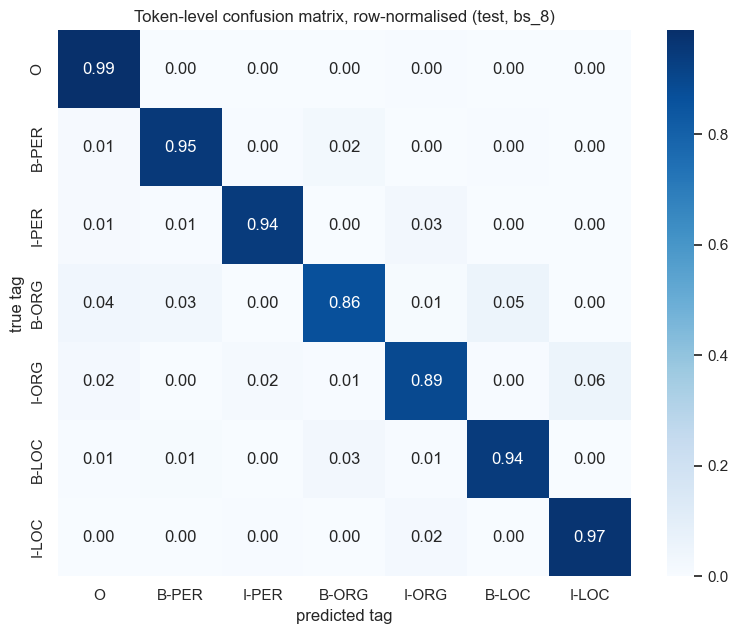

In [36]:
flat_true = [tag for sentence in y_true for tag in sentence]
flat_pred = [tag for sentence in y_pred for tag in sentence]
cm = confusion_matrix(flat_true, flat_pred, labels=label_list)
cm_norm = np.divide(cm, cm.sum(axis=1, keepdims=True), out=np.zeros(cm.shape), where=cm.sum(axis=1, keepdims=True) > 0)

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=label_list, yticklabels=label_list, ax=ax)
ax.set_xlabel("predicted tag")
ax.set_ylabel("true tag")
ax.set_title(f"Token-level confusion matrix, row-normalised (test, {best_name})")
plt.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "test_confusion_matrix.png"), dpi=150, bbox_inches="tight")
plt.show()

In [37]:
# Nekoliko test recenica sa barem jednom pogresnom oznakom (analiza gresaka)
errors = [i for i, (t, p) in enumerate(zip(y_true, y_pred)) if t != p]
print(f"sentences with at least one error: {len(errors)} / {len(y_true)}\n")

for i in errors[:5]:
    words = ds["test"][i]["tokens"]
    print("words:", " ".join(words))
    print("gold :", " ".join(f"{w}/{t}" for w, t in zip(words, y_true[i]) if t != "O"))
    print("pred :", " ".join(f"{w}/{p}" for w, p in zip(words, y_pred[i]) if p != "O"))
    print()

sentences with at least one error: 1144 / 10000

words: су одржани 19. маја и видели су победу Хришћанске демократије , која је формирала владу .
gold : 19./B-LOC маја/I-LOC Хришћанске/B-ORG демократије/I-ORG
pred : Хришћанске/B-ORG демократије/I-ORG

words: Победници Ролан Гароса - жене појединачно
gold : Победници/B-ORG Ролан/I-ORG Гароса/I-ORG -/I-ORG жене/I-ORG појединачно/I-ORG
pred : Победници/B-ORG Ролан/B-PER Гароса/I-ORG -/I-ORG жене/I-ORG појединачно/I-ORG

words: `` Великог Торина '' и њено продужење ка Милану преко Новаре и Верћелија .
gold : Великог/B-LOC Торина/I-LOC Милану/B-LOC Новаре/B-LOC Верћелија/B-ORG
pred : Милану/B-LOC Новаре/B-LOC Верћелија/B-LOC

words: На почетку свог постојања улази у коалцију ДЕПОС са СПО , ДСС и ГСС .
gold : ДЕПОС/B-ORG СПО/B-ORG ДСС/B-ORG ГСС/B-ORG
pred : СПО/B-ORG ДСС/B-ORG ГСС/B-ORG

words: Траписти изградили творницу пива .
gold : творницу/B-ORG пива/I-ORG
pred : Траписти/B-ORG



### Grafovi

#### Loss

Gubitak pri obuci (beleži se svakih 50 koraka) i gubitak pri validaciji (nakon svake epohe) za svaki eksperiment. Gubitak pri validaciji koji raste dok gubitak pri obuci konstantno opada ukazuje na prenaucenost.

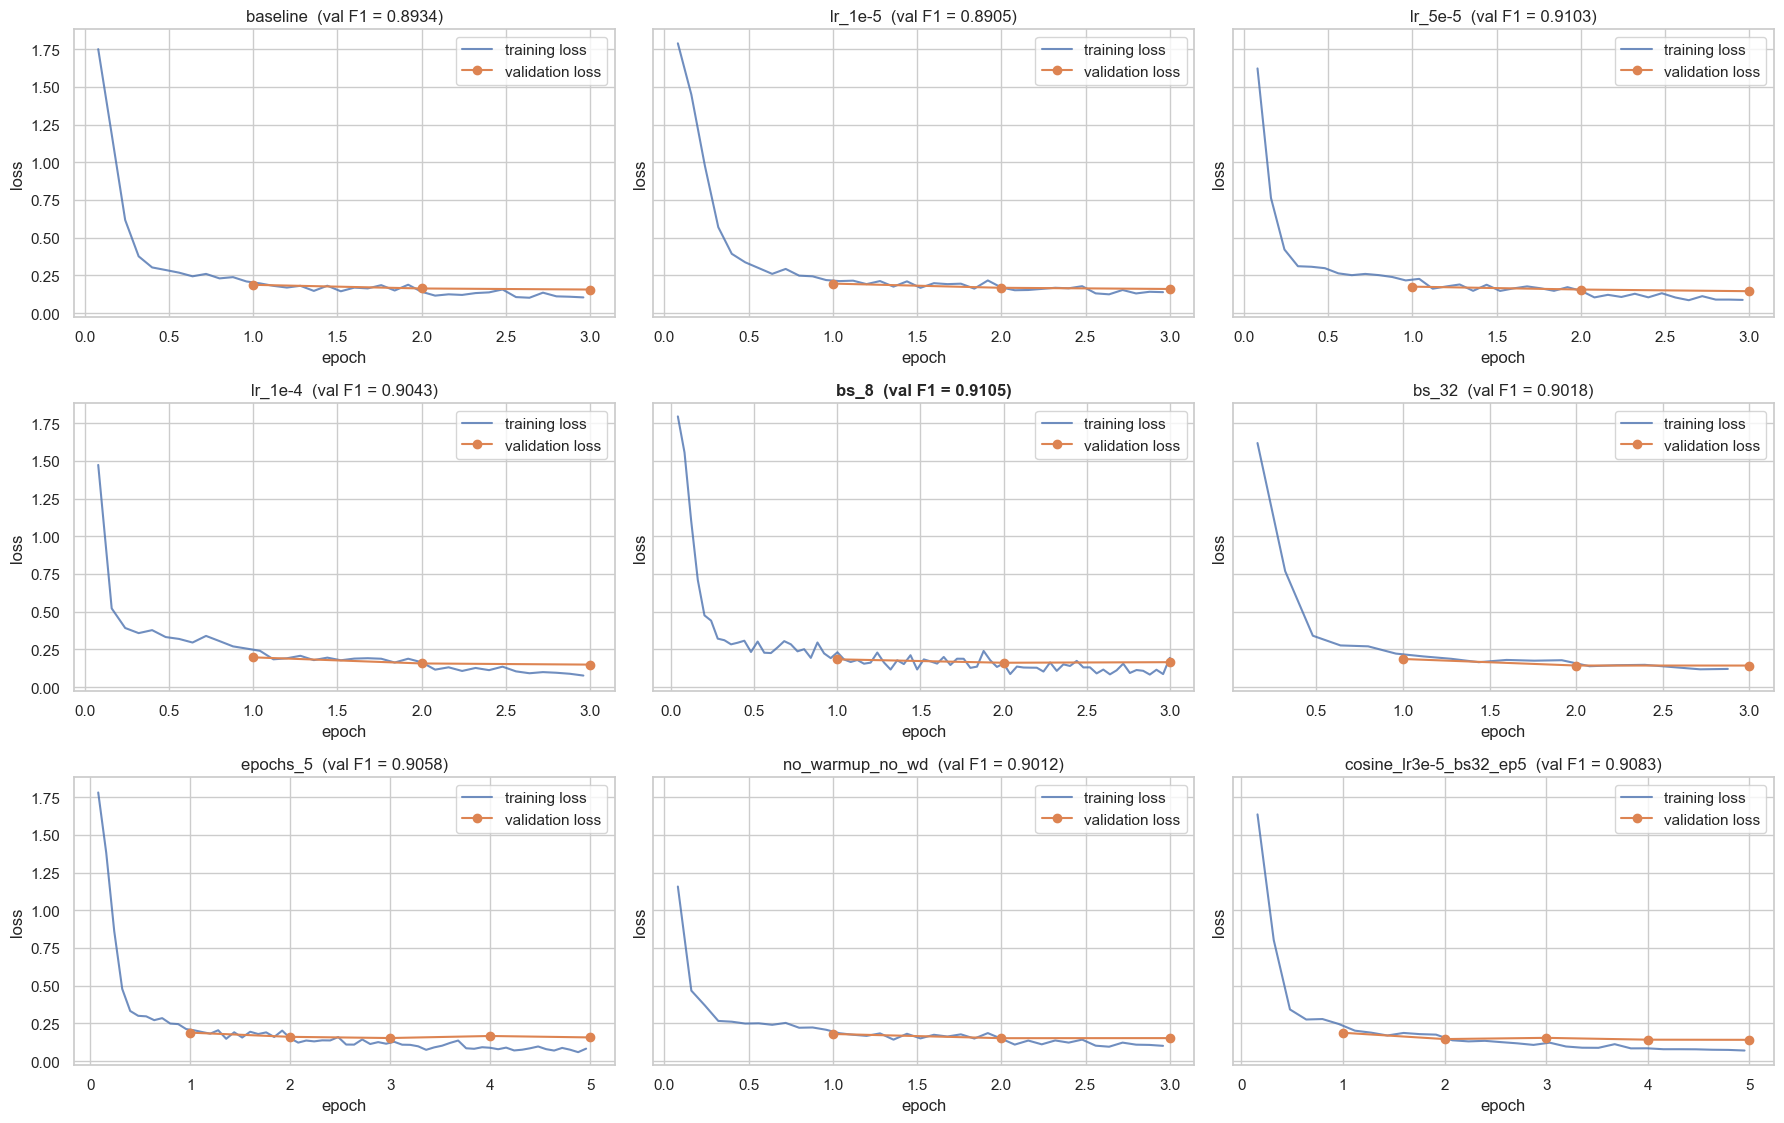

In [38]:
names = list(RESULTS)
ncols = 3
nrows = int(np.ceil(len(names) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 3.8 * nrows), sharey=True, squeeze=False)

for ax, name in zip(axes.flat, names):
    h = HISTORIES[name]
    ax.plot(h["train"]["epoch"], h["train"]["loss"], label="training loss", alpha=0.8)
    ax.plot(h["eval"]["epoch"], h["eval"]["loss"], "o-", label="validation loss")
    ax.set_title(f"{name}  (val F1 = {RESULTS[name]['val_f1']:.4f})", fontweight="bold" if name == best_name else None)
    ax.set_xlabel("epoch")
    ax.set_ylabel("loss")
    ax.legend()
for ax in axes.flat[len(names):]:
    ax.axis("off")

plt.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "loss_curves.png"), dpi=150, bbox_inches="tight")
plt.show()

#### F1

Validacija F1 i gubitak validacije nakon svake epohe, svi eksperimenti na jednom grafu.

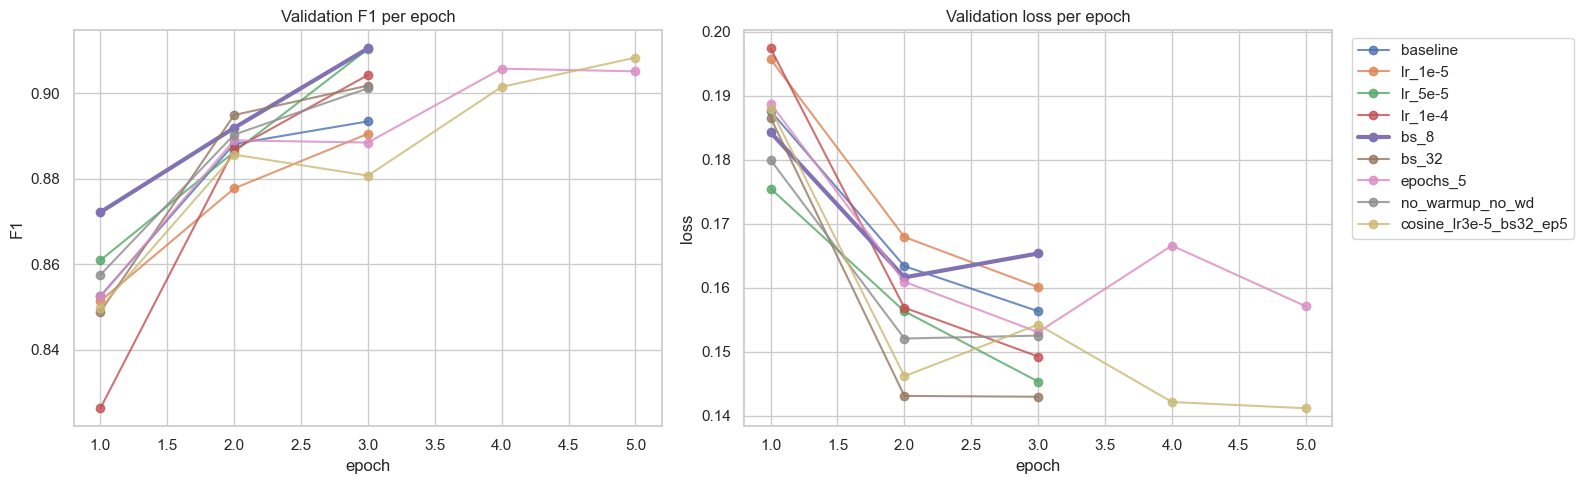

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for name in names:
    h = HISTORIES[name]["eval"]
    style = dict(linewidth=3) if name == best_name else dict(linewidth=1.5, alpha=0.8)
    axes[0].plot(h["epoch"], h["f1"], "o-", label=name, **style)
    axes[1].plot(h["epoch"], h["loss"], "o-", label=name, **style)

axes[0].set_title("Validation F1 per epoch")
axes[0].set_ylabel("F1")
axes[1].set_title("Validation loss per epoch")
axes[1].set_ylabel("loss")
for ax in axes:
    ax.set_xlabel("epoch")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "f1_per_epoch.png"), dpi=150, bbox_inches="tight")
plt.show()

#### Poredjenje eksperimenata

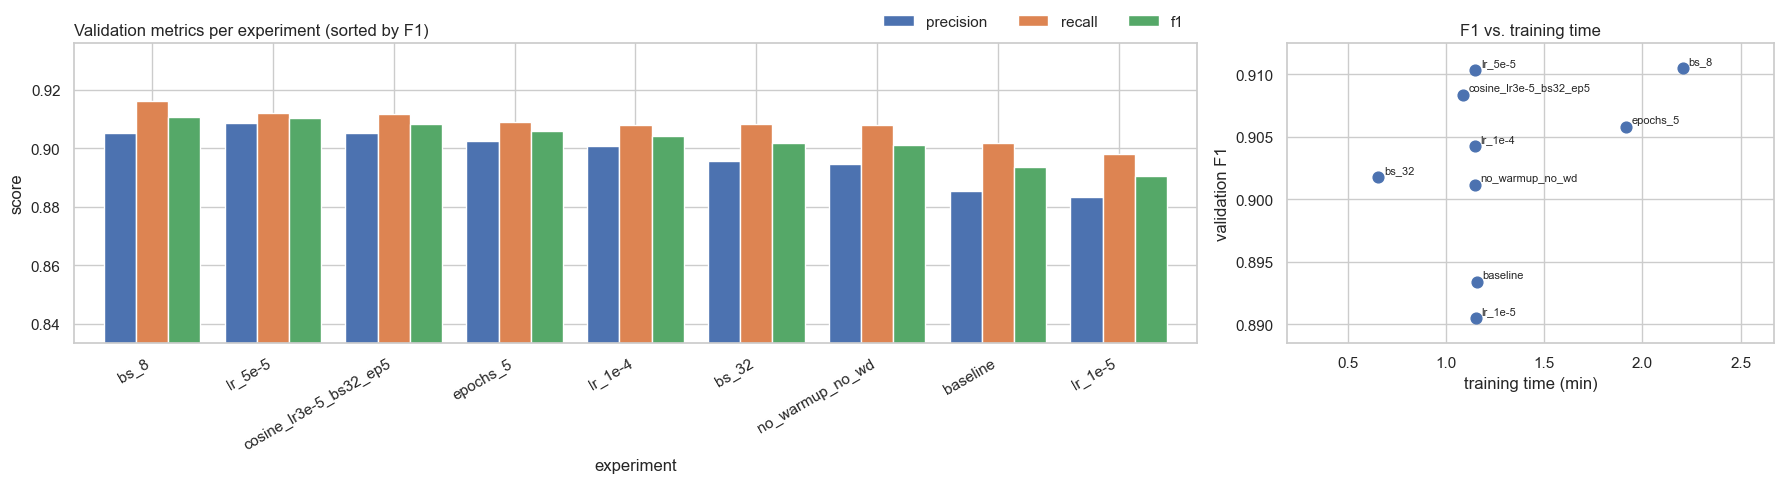

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={"width_ratios": [3, 1.3]})

plot_df = comparison[["val_precision", "val_recall", "val_f1"]].rename(columns=lambda c: c.replace("val_", ""))
plot_df.plot.bar(ax=axes[0], rot=30, width=0.8)
axes[0].set_ylim(max(0.0, plot_df.values.min() - 0.05), min(1.0, plot_df.values.max() + 0.02))
axes[0].set_title("Validation metrics per experiment (sorted by F1)", loc="left")
axes[0].set_ylabel("score")
for label in axes[0].get_xticklabels():
    label.set_horizontalalignment("right")
axes[0].legend(ncol=3, loc="lower right", bbox_to_anchor=(1.0, 1.0), frameon=False)

axes[1].scatter(comparison["train_time_min"], comparison["val_f1"], s=60)
for name, r in comparison.iterrows():
    axes[1].annotate(name, (r["train_time_min"], r["val_f1"]), fontsize=8, xytext=(4, 3), textcoords="offset points")
axes[1].set_xlabel("training time (min)")
axes[1].set_ylabel("validation F1")
axes[1].set_title("F1 vs. training time")
axes[1].margins(x=0.3, y=0.1)

plt.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "experiment_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()

#### Test rezultati po klasi

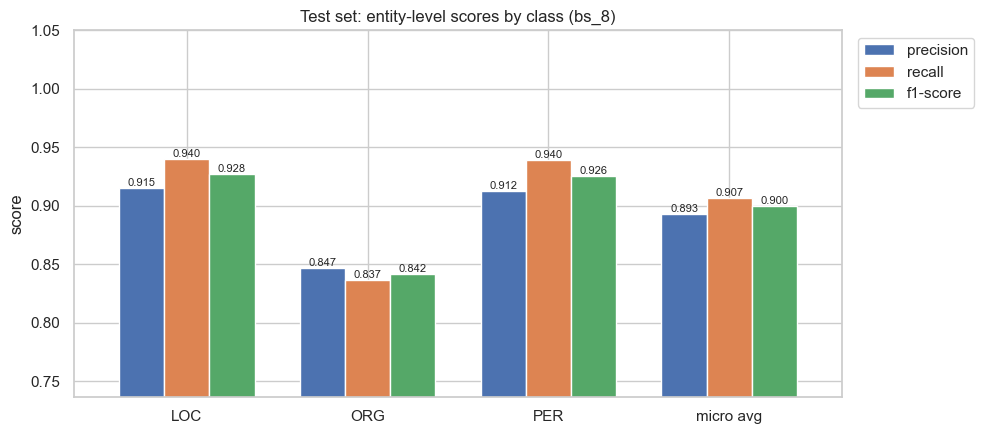

In [41]:
class_df = per_class_df.loc[ENTITY_TYPES + ["micro avg"], ["precision", "recall", "f1-score"]]

ax = class_df.plot.bar(figsize=(10, 4.5), rot=0, width=0.75)
ax.set_ylim(max(0.0, class_df.values.min() - 0.1), 1.05)
ax.set_title(f"Test set: entity-level scores by class ({best_name})")
ax.set_ylabel("score")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
ax.figure.savefig(os.path.join(RESULTS_DIR, "test_scores_by_class.png"), dpi=150, bbox_inches="tight")
plt.show()

### Rezime i brza provera zakljucivanja

In [42]:
print(f"Best experiment : {best_name}")
print(f"Hyperparameters : { {k: RESULTS[best_name][k] for k in BASELINE_HP} }")
print(f"Validation F1   : {comparison.loc[best_name, 'val_f1']:.4f}")
print(f"Test P / R / F1 : {test_overall['precision']:.4f} / {test_overall['recall']:.4f} / {test_overall['f1']:.4f}")
print(f"Results & plots : {os.path.abspath(RESULTS_DIR)}")
print(f"Best model      : {os.path.abspath(BEST_MODEL_DIR)}")

Best experiment : bs_8
Hyperparameters : {'learning_rate': 2e-05, 'per_device_train_batch_size': 8, 'num_train_epochs': 3, 'weight_decay': 0.01, 'warmup_ratio': 0.1, 'lr_scheduler_type': 'linear'}
Validation F1   : 0.9105
Test P / R / F1 : 0.8931 / 0.9071 / 0.9000
Results & plots : c:\Users\stefa\Documents\Pajton kodovi\NLP\ner_roberta_sr\results
Best model      : c:\Users\stefa\Documents\Pajton kodovi\NLP\ner_roberta_sr\best_model


In [43]:
ner = pipeline(
    "token-classification",
    model=best_model,
    tokenizer=tokenizer,
    aggregation_strategy="simple",          # merge sub-tokens / B-I tags into whole entities
    device=0 if torch.cuda.is_available() else -1,
)

sentences = [
    "Никола Тесла је рођен у Смиљану, а касније је радио у Њујорку за компанију Вестингхаус.",
    "Novak Đoković je posetio Beograd i sastao se sa predstavnicima Teniskog saveza Srbije.",
    "Elektronski fakultet je clan Univerziteta u Nisu."
]
for sentence in sentences:
    print(sentence)
    display(pd.DataFrame(ner(sentence))[["entity_group", "word", "score"]].round(3))

Никола Тесла је рођен у Смиљану, а касније је радио у Њујорку за компанију Вестингхаус.


,entity_group,word,score
0,PER,Никола Тесла,0.993
1,LOC,С,0.991
2,LOC,ми,0.984
3,LOC,ља,0.704
4,LOC,Њујорк,0.997
5,ORG,Вестингхаус,0.894


Novak Đoković je posetio Beograd i sastao se sa predstavnicima Teniskog saveza Srbije.


,entity_group,word,score
0,PER,Nova,0.998
1,PER,k Đoković,0.965
2,LOC,Beograd,0.980
3,ORG,Teniskog saveza Srbije,0.976


Elektronski fakultet je clan Univerziteta u Nisu.


,entity_group,word,score
0,ORG,Elektron,0.792
1,ORG,fakultet,0.822
2,ORG,Univerziteta u Nisu,0.994
